# Exploratory Data Analysis (EDA)
Bank Transaction Fraud Detection

> **Overview:** In this EDA *we dig deep into the Bank Transaction Fraud Detection dataset* — Our goal goes beyond just plotting charts; *"we aim to uncover underlying patterns, identify anomalies, and discover actionable ways to tackle fraud effectively."*

**Our plan (the EDA workflow):**
1. Load and look at the data
2. Understand the columns
3. Clean the data (missing values)
4. Explore one column at a time (distributions)
5. Explore relationships between columns
6. Write down our insights


## 0. Setup — import the tools we need

In [27]:
import pandas as pd          # for working with tables of data
import numpy as np            # for numbers and math
import matplotlib.pyplot as plt   # for charts
import seaborn as sns         # for nicer charts (and it gives us the Titanic dataset)

# make our charts look clean
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)

print("Libraries loaded successfully!")

Libraries loaded successfully!


## 1. Load the data and take a first look



In [50]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "bank_fraud.csv"

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "nafiulislam490/bank-transaction-fraud-detection-dataset",
    file_path,
)


print("First 5 records:", df.head())# Load the dataset into a DataFrame
pd.set_option('display.max_columns', None)# To make sure of showing all columns
df.head()# shows the first 5 rows

Using Colab cache for faster access to the 'bank-transaction-fraud-detection-dataset' dataset.
First 5 records:   transaction_id   customer_id transaction_date transaction_time  hour_of_day  \
0  TXN0000000001  CUST00121959       2023-08-17         21:13:00           21   
1  TXN0000000002  CUST00146868       2024-02-06         05:16:00            5   
2  TXN0000000003  CUST00131933       2024-06-28         12:15:00           12   
3  TXN0000000004  CUST00103695       2023-03-16         02:53:00            2   
4  TXN0000000005  CUST00119880       2024-07-12         12:39:00           12   

   is_weekend  is_night_transaction country       city merchant_category  \
0           0                     0     USA     London           Grocery   
1           0                     1      UK   New York        Healthcare   
2           0                     0  Canada      Delhi           Grocery   
3           0                     1  France      Tokyo         Utilities   
4           0        

,transaction_id,customer_id,transaction_date,transaction_time,hour_of_day,is_weekend,is_night_transaction,country,city,merchant_category,payment_method,device_type,customer_age,credit_score,account_age_years,account_balance,transaction_amount,num_prev_transactions,transaction_freq_monthly,distance_from_home_km,time_since_last_txn_hrs,is_international,failed_attempts,pin_changed_recently,is_fraud,fraud_type
0,TXN0000000001,CUST00121959,2023-08-17,21:13:00,21,0,0,USA,London,Grocery,Bank Transfer,POS Terminal,18,695,7.2,369.36,39.49,157,23,52.7,10.20,0,0,0,0,NaN
1,TXN0000000002,CUST00146868,2024-02-06,05:16:00,5,0,1,UK,New York,Healthcare,Cheque,Desktop,30,600,8.6,2681.99,153.71,153,23,0.9,12.47,0,0,0,0,NaN
2,TXN0000000003,CUST00131933,2024-06-28,12:15:00,12,0,0,Canada,Delhi,Grocery,Crypto,Mobile,20,711,10.8,44590.64,118.20,161,20,9.2,0.08,0,1,0,0,NaN
3,TXN0000000004,CUST00103695,2023-03-16,02:53:00,2,0,1,France,Tokyo,Utilities,Debit Card,Mobile,29,711,7.3,1213.37,49.50,160,25,14.8,17.94,1,0,1,1,Synthetic Identity
4,TXN0000000005,CUST00119880,2024-07-12,12:39:00,12,0,0,Canada,Melbourne,Clothing,Debit Card,Desktop,49,751,11.8,34615.01,30.74,134,18,38.9,2.16,0,0,0,0,NaN


• Successfully loaded the dataset to preview the first 5 rows and verify all columns.

• Identified key transactional attributes (e.g., date, time, country, merchant, and device type) that will be used to detect fraud patterns.

## 2. Understand the data

In [29]:
print("How many rows and columns?")
print("Shape (rows, columns):", df.shape) # How many rows and columns

How many rows and columns?
Shape (rows, columns): (1000000, 26)


In [30]:
df.info()# shows every column, how many values are filled, and the data type

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 26 columns):
 #   Column                    Non-Null Count    Dtype  
---  ------                    --------------    -----  
 0   transaction_id            1000000 non-null  object 
 1   customer_id               1000000 non-null  object 
 2   transaction_date          1000000 non-null  object 
 3   transaction_time          1000000 non-null  object 
 4   hour_of_day               1000000 non-null  int64  
 5   is_weekend                1000000 non-null  int64  
 6   is_night_transaction      1000000 non-null  int64  
 7   country                   1000000 non-null  object 
 8   city                      1000000 non-null  object 
 9   merchant_category         1000000 non-null  object 
 10  payment_method            1000000 non-null  object 
 11  device_type               1000000 non-null  object 
 12  customer_age              1000000 non-null  int64  
 13  credit_score              10

There is missing data look at `fraud_type`.

In [31]:
# .describe() gives quick statistics for the NUMBER columns:
# count, mean (average), min, max, etc.
df.describe()

,hour_of_day,is_weekend,is_night_transaction,customer_age,credit_score,account_age_years,account_balance,transaction_amount,num_prev_transactions,transaction_freq_monthly,distance_from_home_km,time_since_last_txn_hrs,is_international,failed_attempts,pin_changed_recently,is_fraud
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.00000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,11.496978,0.286022,0.375057,41.771678,679.028781,4.987911,16594.25442,204.724665,149.996350,19.999322,20.009890,12.000945,0.149994,0.380072,0.080439,0.055255
std,6.923751,0.451900,0.484138,13.424588,78.828748,4.925949,28171.46068,459.567802,12.244379,4.474045,20.011427,11.999904,0.357066,0.914603,0.271972,0.228477
min,0.000000,0.000000,0.000000,18.000000,300.000000,0.100000,100.00000,1.000000,96.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.000000,0.000000,0.000000,32.000000,625.000000,1.400000,3609.01750,33.400000,142.000000,17.000000,5.800000,3.450000,0.000000,0.000000,0.000000,0.000000
50%,11.000000,0.000000,0.000000,42.000000,680.000000,3.500000,8092.12000,73.120000,150.000000,20.000000,13.900000,8.320000,0.000000,0.000000,0.000000,0.000000
75%,18.000000,1.000000,1.000000,51.000000,734.000000,6.900000,18225.02500,181.450000,158.000000,23.000000,27.700000,16.630000,0.000000,0.000000,0.000000,0.000000
max,23.000000,1.000000,1.000000,85.000000,850.000000,30.000000,500000.00000,46129.600000,213.000000,44.000000,292.100000,154.200000,1.000000,5.000000,1.000000,1.000000


 **note:**
- The **averge** of `transaction_freq_monthly` is **19.999322** and `customer_age` is **41**.
- The **max** of `failed_attmpts` is **5**.

## 3. Clean the data — find and handle missing values

In [32]:
# Count how many values are missing in each column, sorted from most to least
df.isnull().sum().sort_values(ascending=False)

,0
fraud_type,944745
transaction_id,0
transaction_date,0
transaction_time,0
hour_of_day,0
is_weekend,0
is_night_transaction,0
country,0
city,0
customer_id,0


We found the number of **null** in the `fraud_type` **944745**, and this is a big problem as this column is **important**.

In [33]:
print(df['fraud_type'].value_counts())

fraud_type
Phishing              9252
Account Takeover      9232
Synthetic Identity    9214
Card Cloning          9200
Friendly Fraud        9187
Identity Theft        9170
Name: count, dtype: int64


- Explored `fraud_type` column to find out the reason fo the **null**.

In [34]:
null_count = df['fraud_type'].isnull().sum()

print("num of null in (fraud_type):", null_count)

num of null in (fraud_type): 944745


In [35]:
df[df['fraud_type'].isnull()].head() # showe null in (fraud_type) with all column

,transaction_id,customer_id,transaction_date,transaction_time,hour_of_day,is_weekend,is_night_transaction,country,city,merchant_category,payment_method,device_type,customer_age,credit_score,account_age_years,account_balance,transaction_amount,num_prev_transactions,transaction_freq_monthly,distance_from_home_km,time_since_last_txn_hrs,is_international,failed_attempts,pin_changed_recently,is_fraud,fraud_type
0,TXN0000000001,CUST00121959,2023-08-17,21:13:00,21,0,0,USA,London,Grocery,Bank Transfer,POS Terminal,18,695,7.2,369.36,39.49,157,23,52.7,10.20,0,0,0,0,NaN
1,TXN0000000002,CUST00146868,2024-02-06,05:16:00,5,0,1,UK,New York,Healthcare,Cheque,Desktop,30,600,8.6,2681.99,153.71,153,23,0.9,12.47,0,0,0,0,NaN
2,TXN0000000003,CUST00131933,2024-06-28,12:15:00,12,0,0,Canada,Delhi,Grocery,Crypto,Mobile,20,711,10.8,44590.64,118.20,161,20,9.2,0.08,0,1,0,0,NaN
4,TXN0000000005,CUST00119880,2024-07-12,12:39:00,12,0,0,Canada,Melbourne,Clothing,Debit Card,Desktop,49,751,11.8,34615.01,30.74,134,18,38.9,2.16,0,0,0,0,NaN
6,TXN0000000007,CUST00054887,2020-09-05,19:22:00,19,1,0,USA,Mumbai,Education,Debit Card,Mobile,56,733,4.6,11202.02,92.53,178,14,5.0,7.50,1,0,1,0,NaN


- After examining the data, we found a correlation between the **null** and there is no fraud through the `is_fraud =` **0** .

In [36]:
# Make a copy so we keep the original safe
df_clean = df.copy()

df['fraud_type'] = df['fraud_type'].fillna('Legitimate') # Replace the Null with "Legitimate"
print("Filled missing in fraud_type with: Legitimate")

# Check again - there should be far fewer (or no) missing values now
df.isnull().sum().sort_values(ascending=False)

# Check again - there should be far fewer (or no) missing values now
df_clean.isnull().sum().sort_values(ascending=False).head()

Filled missing in fraud_type with: Legitimate


,0
fraud_type,944745
transaction_id,0
transaction_date,0
transaction_time,0
hour_of_day,0


In [37]:
df.head()

,transaction_id,customer_id,transaction_date,transaction_time,hour_of_day,is_weekend,is_night_transaction,country,city,merchant_category,payment_method,device_type,customer_age,credit_score,account_age_years,account_balance,transaction_amount,num_prev_transactions,transaction_freq_monthly,distance_from_home_km,time_since_last_txn_hrs,is_international,failed_attempts,pin_changed_recently,is_fraud,fraud_type
0,TXN0000000001,CUST00121959,2023-08-17,21:13:00,21,0,0,USA,London,Grocery,Bank Transfer,POS Terminal,18,695,7.2,369.36,39.49,157,23,52.7,10.20,0,0,0,0,Legitimate
1,TXN0000000002,CUST00146868,2024-02-06,05:16:00,5,0,1,UK,New York,Healthcare,Cheque,Desktop,30,600,8.6,2681.99,153.71,153,23,0.9,12.47,0,0,0,0,Legitimate
2,TXN0000000003,CUST00131933,2024-06-28,12:15:00,12,0,0,Canada,Delhi,Grocery,Crypto,Mobile,20,711,10.8,44590.64,118.20,161,20,9.2,0.08,0,1,0,0,Legitimate
3,TXN0000000004,CUST00103695,2023-03-16,02:53:00,2,0,1,France,Tokyo,Utilities,Debit Card,Mobile,29,711,7.3,1213.37,49.50,160,25,14.8,17.94,1,0,1,1,Synthetic Identity
4,TXN0000000005,CUST00119880,2024-07-12,12:39:00,12,0,0,Canada,Melbourne,Clothing,Debit Card,Desktop,49,751,11.8,34615.01,30.74,134,18,38.9,2.16,0,0,0,0,Legitimate


- Exploring the data to ensure that the changes were made correctly.

In [38]:
df['customer_serial_num'] = df.groupby('customer_id').ngroup() + 1
# Creating a new column that assigns a serial number to each unique client starting from 1

In [39]:
df['account_transaction_count'] = df.groupby('customer_id')['transaction_id'].transform('count')
# Calculate the number of transactions for each account and store them in a new column within the same table

**Built two new columns:**
- `customer_serial_num`,a serial number to each unique client starting from 1.
- `account_transaction_count`,the number of transactions for each account.

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 28 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   transaction_id             1000000 non-null  object 
 1   customer_id                1000000 non-null  object 
 2   transaction_date           1000000 non-null  object 
 3   transaction_time           1000000 non-null  object 
 4   hour_of_day                1000000 non-null  int64  
 5   is_weekend                 1000000 non-null  int64  
 6   is_night_transaction       1000000 non-null  int64  
 7   country                    1000000 non-null  object 
 8   city                       1000000 non-null  object 
 9   merchant_category          1000000 non-null  object 
 10  payment_method             1000000 non-null  object 
 11  device_type                1000000 non-null  object 
 12  customer_age               1000000 non-null  int64  
 13  credit_score 

In [41]:
df.head()

,transaction_id,customer_id,transaction_date,transaction_time,hour_of_day,is_weekend,is_night_transaction,country,city,merchant_category,payment_method,device_type,customer_age,credit_score,account_age_years,account_balance,transaction_amount,num_prev_transactions,transaction_freq_monthly,distance_from_home_km,time_since_last_txn_hrs,is_international,failed_attempts,pin_changed_recently,is_fraud,fraud_type,customer_serial_num,account_transaction_count
0,TXN0000000001,CUST00121959,2023-08-17,21:13:00,21,0,0,USA,London,Grocery,Bank Transfer,POS Terminal,18,695,7.2,369.36,39.49,157,23,52.7,10.20,0,0,0,0,Legitimate,121171,6
1,TXN0000000002,CUST00146868,2024-02-06,05:16:00,5,0,1,UK,New York,Healthcare,Cheque,Desktop,30,600,8.6,2681.99,153.71,153,23,0.9,12.47,0,0,0,0,Legitimate,145900,10
2,TXN0000000003,CUST00131933,2024-06-28,12:15:00,12,0,0,Canada,Delhi,Grocery,Crypto,Mobile,20,711,10.8,44590.64,118.20,161,20,9.2,0.08,0,1,0,0,Legitimate,131076,3
3,TXN0000000004,CUST00103695,2023-03-16,02:53:00,2,0,1,France,Tokyo,Utilities,Debit Card,Mobile,29,711,7.3,1213.37,49.50,160,25,14.8,17.94,1,0,1,1,Synthetic Identity,103040,3
4,TXN0000000005,CUST00119880,2024-07-12,12:39:00,12,0,0,Canada,Melbourne,Clothing,Debit Card,Desktop,49,751,11.8,34615.01,30.74,134,18,38.9,2.16,0,0,0,0,Legitimate,119109,5


- Exploring the data to ensure that the changes were made correctly.

## 4. Explore one column at a time (distributions)

This visualization compares the total monetary volume of fraudulent transactions against legitimate ones. It provides a clear overview of the financial impact of fraud within the dataset, highlighting the proportion of funds at risk.

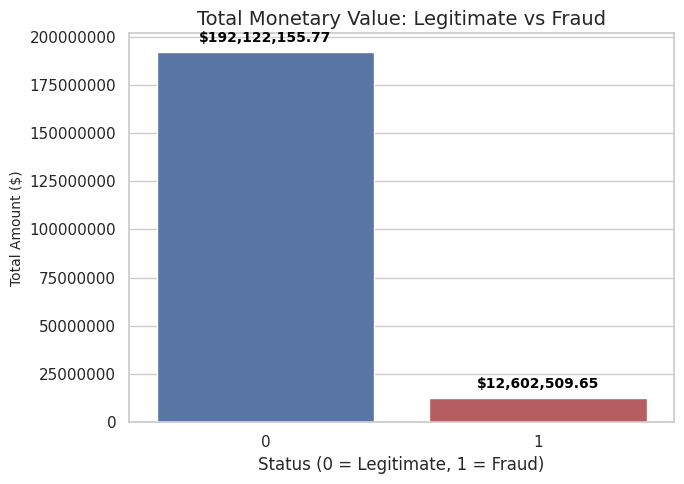

Total amounts transferred correctly: $192,122,155.77
Total amounts transferred correctly: $12,602,509.65
Percentage of stolen funds out of total funds: 6.16%


In [42]:
total_money = df.groupby('is_fraud')['transaction_amount'].sum().reset_index()

plt.figure(figsize=(7, 5))
ax = sns.barplot(x='is_fraud', y='transaction_amount', data=total_money,
                 hue='is_fraud', palette=['#4C72B0', '#C44E52'], legend=False)

plt.title('Total Monetary Value: Legitimate vs Fraud', fontsize=14)
plt.xlabel('Status (0 = Legitimate, 1 = Fraud)', fontsize=12)
plt.ylabel('Total Amount ($)', fontsize=10)

for p in ax.patches:
    amount = p.get_height()
    ax.annotate(f'${amount:,.2f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='black',
                xytext=(0, 5), textcoords='offset points')
ax.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

legitimate_total = total_money[total_money['is_fraud'] == 0]['transaction_amount'].values[0]
fraud_total = total_money[total_money['is_fraud'] == 1]['transaction_amount'].values[0]
total_all = legitimate_total + fraud_total
fraud_percentage = (fraud_total / total_all) * 100

print(f"Total amounts transferred correctly: ${legitimate_total:,.2f}")
print(f"Total amounts transferred correctly: ${fraud_total:,.2f}")
print(f"Percentage of stolen funds out of total funds: {fraud_percentage:.2f}%")

This visualization illustrates the distribution of users based on their PIN change activity. It highlights the percentage of customers who have updated their security credentials versus those who have never done so.

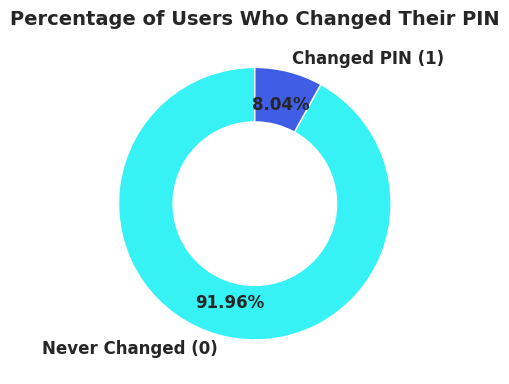


---Distributing the password change in the data---
Percentage of those who have never changed their passwords: 91.96%
A percentage of those who changed their passwords: 8.04%


In [43]:
pin_percentages = df['pin_changed_recently'].value_counts(normalize=True) * 100

plt.figure(figsize=(6, 4))

labels = ['Never Changed (0)', 'Changed PIN (1)']
colors = ["#37F2F5", "#3F5DE5"]

plt.pie(
    pin_percentages,
    labels=labels,
    colors=colors,
    autopct='%1.2f%%',
    startangle=90,
    pctdistance=0.75,
    textprops={'fontsize': 12, 'weight': 'bold'},
    wedgeprops=dict(width=0.4, edgecolor='white')
)

plt.title('Percentage of Users Who Changed Their PIN', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n---Distributing the password change in the data---")
print(f"Percentage of those who have never changed their passwords: {pin_percentages[0]:.2f}%")
print(f"A percentage of those who changed their passwords: {pin_percentages[1]:.2f}%")

This visualization illustrates the distribution of fraud and legitimate transactions in the dataset.

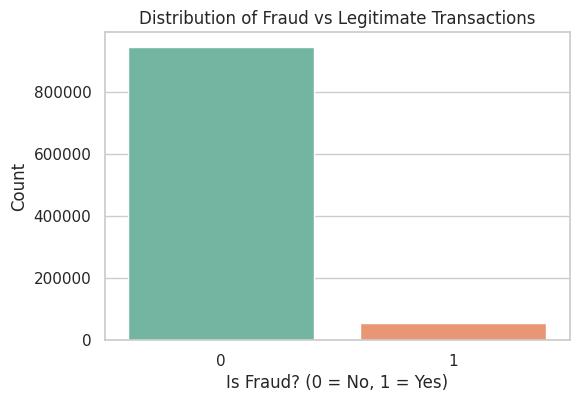

In [44]:
plt.figure(figsize=(6,4))

sns.countplot(x='is_fraud', data=df, palette='Set2', hue='is_fraud', legend=False)
plt.title('Distribution of Fraud vs Legitimate Transactions')
plt.xlabel('Is Fraud? (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

## 5. Explore relationships between columns


This visualization focuses on the age distribution of customers involved in fraudulent transactions. It helps identify trends and determine whether certain age groups are more susceptible to fraudulent activities.

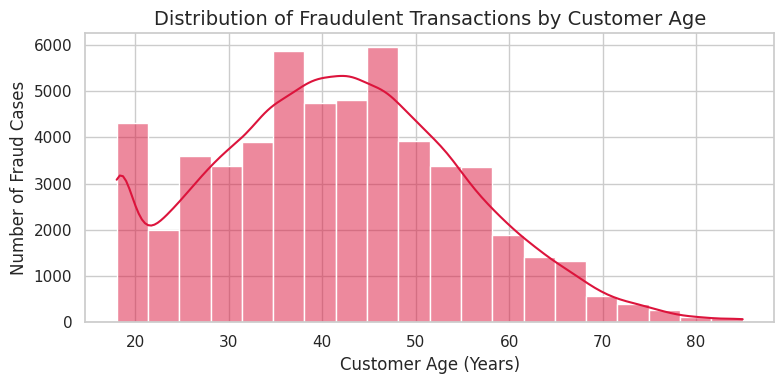

In [45]:
fraud_data = df[df['is_fraud'] == 1].copy()

plt.figure(figsize=(8, 4))

sns.histplot(data=fraud_data, x='customer_age', bins=20, kde=True, color='crimson')
plt.title('Distribution of Fraudulent Transactions by Customer Age', fontsize=14)
plt.xlabel('Customer Age (Years)', fontsize=12)
plt.ylabel('Number of Fraud Cases', fontsize=12)
plt.tight_layout()
plt.show()

To better analyze fraud patterns, customer ages were grouped into age categories instead of using individual ages. The objective is to identify whether fraudulent transactions are concentrated within a specific age group.

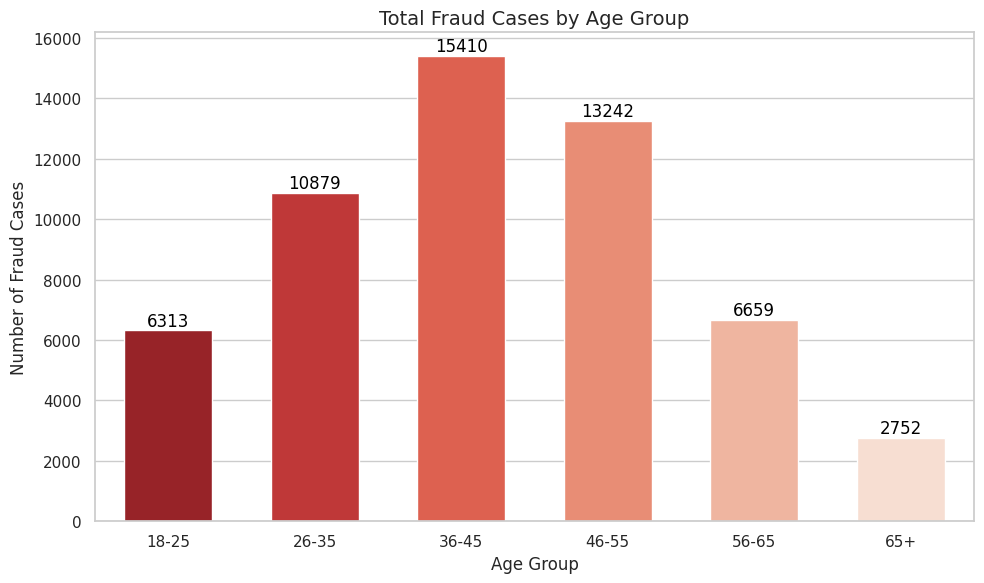

In [46]:
bins = [18, 25, 35, 45, 55, 65, 100]
labels = ['18-25', '26-35', '36-45', '46-55', '56-65', '65+']


fraud_data['age_group'] = pd.cut(fraud_data['customer_age'], bins=bins, labels=labels, right=False)

age_group_counts = fraud_data['age_group'].value_counts().reset_index()
age_group_counts.columns = ['Age Group', 'Fraud Count']

age_group_counts = age_group_counts.sort_values('Age Group')

plt.figure(figsize=(10, 6))
sns.barplot(x='Age Group', y='Fraud Count', data=age_group_counts, hue='Age Group', palette='Reds_r', legend=False, dodge=False, width=0.6)
plt.title('Total Fraud Cases by Age Group', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Number of Fraud Cases', fontsize=12)

for index, row in enumerate(age_group_counts['Fraud Count']):
    plt.text(index, row + max(age_group_counts['Fraud Count'])*0.01, str(row), color='black', ha="center")

plt.tight_layout()
plt.show()

Fraud rate analysis with night and weekend transfers

Fraud percentage at night vs day:
 is_night_transaction
0    4.066931
1    7.955857
Name: is_fraud, dtype: float64
Fraud percentage on weekends vs weekdays:
 is_weekend
0    5.508293
1    5.568453
Name: is_fraud, dtype: float64


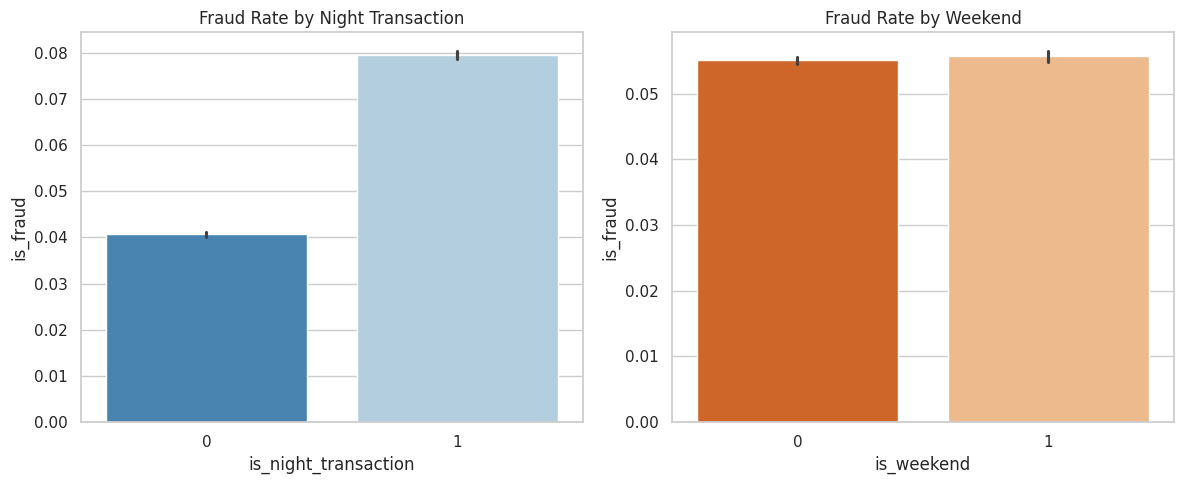

In [47]:
night_fraud = df.groupby('is_night_transaction')['is_fraud'].mean() * 100
print("Fraud percentage at night vs day:\n", night_fraud)

weekend_fraud = df.groupby('is_weekend')['is_fraud'].mean() * 100
print("Fraud percentage on weekends vs weekdays:\n", weekend_fraud)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(x='is_night_transaction', y='is_fraud', data=df, ax=axes[0],
            hue='is_night_transaction', palette='Blues_r', legend=False)
axes[0].set_title('Fraud Rate by Night Transaction')

sns.barplot(x='is_weekend', y='is_fraud', data=df, ax=axes[1],
            hue='is_weekend', palette='Oranges_r', legend=False)
axes[1].set_title('Fraud Rate by Weekend')

plt.tight_layout()
plt.show()

This visualization compares overall transaction activity with fraudulent transactions across merchant categories. The goal is to determine whether specific merchant categories are more frequently targeted by fraudulent activities.

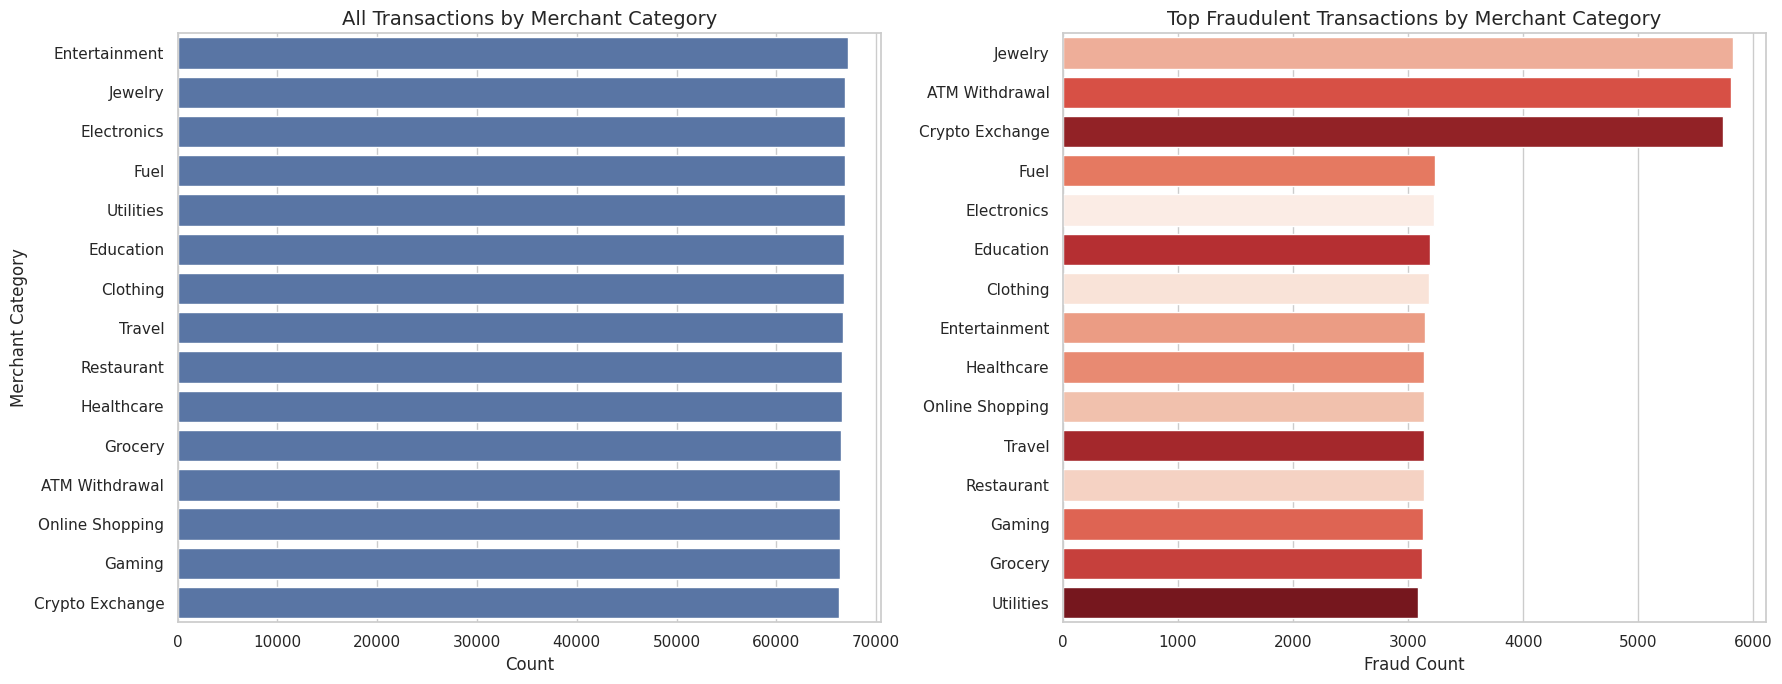

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.countplot(y='merchant_category', data=df,
              order=df['merchant_category'].value_counts().index,
              ax=axes[0], color='#4C72B0')

axes[0].set_title('All Transactions by Merchant Category', fontsize=14)
axes[0].set_xlabel('Count', fontsize=12)
axes[0].set_ylabel('Merchant Category', fontsize=12)

fraud_df = df[df['is_fraud'] == 1]

sns.countplot(y='merchant_category', data=fraud_df,
              order=fraud_df['merchant_category'].value_counts().index,
              ax=axes[1],
              hue='merchant_category',
              palette='Reds_r',
              legend=False)

axes[1].set_title('Top Fraudulent Transactions by Merchant Category', fontsize=14)
axes[1].set_xlabel('Fraud Count', fontsize=12)
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

This visualization examines fraud cases by payment method and fraud type to uncover patterns in fraudulent activities. The goal is to identify high-risk payment methods and the most prevalent fraud techniques, providing insights for targeted fraud prevention strategies.

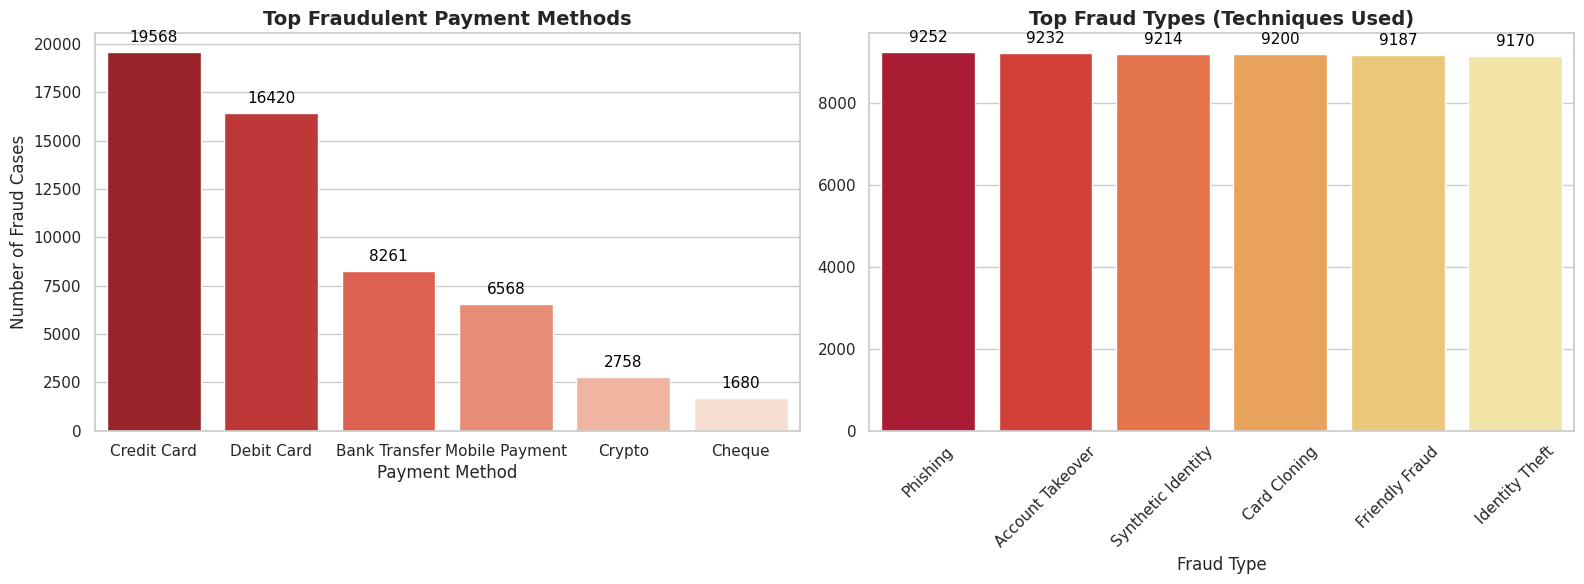

In [49]:
fraud_data = df[df['is_fraud'] == 1].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

payment_counts = fraud_data['payment_method'].value_counts().reset_index()
payment_counts.columns = ['Payment Method', 'Count']

ax1 = sns.barplot(x='Payment Method', y='Count', data=payment_counts,
                  ax=axes[0], hue='Payment Method', palette='Reds_r', legend=False)

axes[0].set_title('Top Fraudulent Payment Methods', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Payment Method', fontsize=12)
axes[0].set_ylabel('Number of Fraud Cases', fontsize=12)

for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height())}',
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=11, color='black',
                 xytext=(0, 5), textcoords='offset points')

fraud_type_data = fraud_data.dropna(subset=['fraud_type'])

type_counts = fraud_type_data['fraud_type'].value_counts().reset_index()
type_counts.columns = ['Fraud Type', 'Count']

ax2 = sns.barplot(x='Fraud Type', y='Count', data=type_counts,
                  ax=axes[1], hue='Fraud Type', palette='YlOrRd_r', legend=False)

axes[1].set_title('Top Fraud Types (Techniques Used)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Fraud Type', fontsize=12)
axes[1].set_ylabel('')

axes[1].tick_params(axis='x', rotation=45)

for p in ax2.patches:
    ax2.annotate(f'{int(p.get_height())}',
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=11, color='black',
                 xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

## 6. Write down the insights

The dataset is highly imbalanced, with legitimate transactions significantly outnumbering fraudulent transactions.

1. **Fraud cases are most common among customers** *aged 36–45*, followed by the *46–55 age* group, suggesting that **middle-aged** customers are more frequently targeted by fraudulent activities.
2. **Fraud cases are distributed across all age groups**, but they decline noticeably after the age of 55, indicating that older customers are less frequently involved in fraudulent transactions.
3. **Certain merchant categories experience higher fraud rates**, particularly Jewelry, ATM Withdrawals, and Crypto Exchange, making them higher-risk sectors for fraudulent transactions.
4. **Credit Cards are the most frequently used payment method in fraudulent transactions**, while Phishing is the most common fraud technique, highlighting the importance of strengthening security measures for card payments and phishing prevention.
5. **The frequencies of different fraud types are relatively similar**, suggesting that fraud is not dominated by a single technique and that detection systems should be designed to identify multiple fraud patterns rather than focusing on one type alone.